# Trading bot fingerprinting with probabilistic automata: data, splits and baseline

This notebook covers steps 2 to 5 of the project workflow for the idea in
[`research/idea_bot_fingerprinting_automata.md`](../../research/idea_bot_fingerprinting_automata.md):

1. **Data.** Collect one week of swap events from Ethereum, validate them, decide who counts as a trader.
2. **Preprocessing and split.** Turn each trader's swaps into a sequence of symbols, split by time and by trader, check for leakage.
3. **Baseline.** Define the tasks, the metrics and the protocol, and score fixed baselines.
4. **Method fit.** Check whether probabilistic automata learned from the sequences do what the idea expects.

The literature review is in [`research/literature/literature_review_bot_fingerprinting.md`](../../research/literature/literature_review_bot_fingerprinting.md)
and the conclusions are in [`research/bot_fingerprinting_writeup.md`](../../research/bot_fingerprinting_writeup.md).

Reusable code lives in `src/scripts/dex_swaps.py` and `src/scripts/trader_automata.py`, with tests in `tests/`.

**Running time.** The download (first run only) takes about 1.5 hours through free public endpoints. With the
data in place the notebook runs in a few minutes.

In [1]:
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

sys.path.append("../scripts")
import dex_swaps as ds
import trader_automata as ta

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 120, "display.float_format", "{:,.3f}".format)

START_BLOCK, N_BLOCKS = 26_100_000, 50_400       # seven days of 12-second blocks from 1 October 2026
TRAIN_END = START_BLOCK + 28_800                 # train: first four days
DEV_END = START_BLOCK + 36_000                   # dev: day five; test: days six and seven
MIN_TRAIN, MIN_QUERY, QUERY_LENGTH = 50, 30, 100 # symbols needed to enrol and to query; query truncation
N_SYMBOLS = ta.ALPHABETS["gap_relation"]

# Chart style: one fixed colour per series, thin lines, quiet grid.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
KIND_COLOR = {"bot": ORANGE, "router_user": BLUE}
plt.rcParams.update({
    "figure.dpi": 90, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 1.4, "legend.frameon": False, "font.size": 9.5,
})

## 1. Data

**What the idea needs.** For many traders, the ordered list of their actions on a decentralized exchange,
and labels saying which traders are bots and of what kind.

**What was available.** The sources named in the idea did not work out:

| Source in the idea | Status |
| --- | --- |
| BigQuery public Ethereum dataset | Needs a Google Cloud account. |
| The Graph | Needs an API key since the hosted service closed. |
| ZeroMEV labels | The public API no longer resolves. |
| Flashbots `mev-inspect`, EigenPhi | No public download or needs a key. |

**What is used instead.** The raw events themselves, read from free public Ethereum RPC endpoints:

- Every swap on a Uniswap V2 or V3 pool, and on forks with the same event (SushiSwap and others), emits a
  `Swap` log. `ds.fetch_swap_logs` collects all of them for a range of blocks.
- For each transaction with a swap, `ds.fetch_transactions` looks up the account that signed it and the
  contract it called.

The window is **seven days: the 50,400 blocks from 26,100,000 to 26,150,399, 1 to 8 October 2026.** There are no bot
labels in this data. Section 2 explains what is used in their place.

In [2]:
chunk_dir = ds.DATA_DIR / "chunks"
expected = [chunk_dir / f"swaps_{a}_{b}.parquet" for a, b in ds.chunk_ranges(START_BLOCK, N_BLOCKS)]
if not all(path.exists() for path in expected):
    ds.download_window(START_BLOCK, N_BLOCKS)        # resumable; about 1.5 hours from scratch

swaps = ds.load_swaps()
swaps = swaps[(swaps["block"] >= START_BLOCK) & (swaps["block"] < START_BLOCK + N_BLOCKS)].reset_index(drop=True)
print(f"{len(swaps):,} swaps from {swaps['timestamp'].min()} to {swaps['timestamp'].max()}")
swaps.head(3).T

1,294,242 swaps from 2026-10-01 20:56:59+00:00 to 2026-10-08 21:34:59+00:00


,0,1,2
block,26100000,26100000,26100000
tx_index,4,4,5
log_index,107,109,116
timestamp,2026-10-01 20:56:59+00:00,2026-10-01 20:56:59+00:00,2026-10-01 20:56:59+00:00
tx_hash,0x01da2724af5785b132757e9eb323ed5152b738e4f2de1047b6afecd839686ea5,0x01da2724af5785b132757e9eb323ed5152b738e4f2de1047b6afecd839686ea5,0xa5a89072992e5b02dc32ed46650c82251102fa4ff561862153f5252082b2e06e
pool,0x60031819a16266d896268cfea5d5be0b6c2b5d75,0x98409d8ca9629fbe01ab1b914ebf304175e384c8,0x60031819a16266d896268cfea5d5be0b6c2b5d75
version,v2,v3,v2
sender,0x1f2f10d1c40777ae1da742455c65828ff36df387,0x1f2f10d1c40777ae1da742455c65828ff36df387,0x666fedd4cdd4e890a5ad20e7b60975409435a64a
recipient,0x1f2f10d1c40777ae1da742455c65828ff36df387,0x1f2f10d1c40777ae1da742455c65828ff36df387,0x666fedd4cdd4e890a5ad20e7b60975409435a64a
amount0,"-132,546,955,657,084,928.000","81,344,707,500,088,048.000","-125,376,321,276,580,240.000"


In [3]:
blocks_with_swaps = swaps["block"].nunique()
checks = pd.Series({
    "swaps": len(swaps),
    "transactions": swaps["tx_hash"].nunique(),
    "pools": swaps["pool"].nunique(),
    "signing accounts": swaps["tx_from"].nunique(),
    "addresses calling pools (senders)": swaps["sender"].nunique(),
    "blocks in the window": N_BLOCKS,
    "blocks with at least one swap": blocks_with_swaps,
    "share of blocks with a swap %": 100 * blocks_with_swaps / N_BLOCKS,
    "swaps per block (mean)": len(swaps) / N_BLOCKS,
    "duplicate events": int(swaps.duplicated(["tx_hash", "log_index"]).sum()),
    "missing values": int(swaps.isna().sum().sum()),
    "swaps on V2-style pools %": 100 * (swaps["version"] == "v2").mean(),
    "swaps where both token amounts have the same sign": int(((swaps["amount0"] > 0) == (swaps["amount1"] > 0)).sum()),
    "swaps with a zero amount": int(((swaps["amount0"] == 0) | (swaps["amount1"] == 0)).sum()),
}, name="value")
display(checks.to_frame())

per_day = swaps.groupby(swaps["timestamp"].dt.floor("D")).agg(swaps=("tx_hash", "size"), transactions=("tx_hash", "nunique"),
                                                             signers=("tx_from", "nunique"), blocks=("block", "nunique"))
per_day

,value
swaps,"1,294,242.000"
transactions,"940,245.000"
pools,"18,514.000"
signing accounts,"118,537.000"
addresses calling pools (senders),"1,446.000"
blocks in the window,"50,400.000"
blocks with at least one swap,"49,803.000"
share of blocks with a swap %,98.815
swaps per block (mean),25.679
duplicate events,0.000


,swaps,transactions,signers,blocks
timestamp,,,,
2026-10-01 00:00:00+00:00,20135,14746,4600,899
2026-10-02 00:00:00+00:00,206194,144466,26293,7093
2026-10-03 00:00:00+00:00,164351,114362,21689,7130
2026-10-04 00:00:00+00:00,199887,137745,25534,7111
2026-10-05 00:00:00+00:00,187007,139378,26869,7089
2026-10-06 00:00:00+00:00,163349,124744,26221,7050
2026-10-07 00:00:00+00:00,175691,131141,27070,7062
2026-10-08 00:00:00+00:00,177628,133663,25922,6369


**Validation.**

- The download is complete: 98.8% of the blocks of the window contain at least one swap, the daily counts
  are even (160,000 to 210,000 swaps on each full day), and there are no duplicate events or missing values.
- The decoding is consistent: in a swap the pool receives one token and pays out the other, so the two
  amounts must have opposite signs. That holds for all but 335 of 1.29 million events.
- Transaction lookups succeeded for every swap.

**What this data does not contain.** It covers pools that emit the Uniswap V2 or V3 swap event. Uniswap V4,
Curve, Balancer and other designs are absent, so a trader's sequence is its activity on these pools only.
Token identities and prices are not collected either: the analysis uses the direction and relative size of
swaps, not their value in dollars.

## 2. Who is a trader, and who is a bot?

A swap log names the address that called the pool (`sender`). This is the key to both questions.

- An ordinary user trades through a **router**: a public contract (Uniswap's routers, aggregators) that
  calls pools on behalf of thousands of different accounts.
- A professional bot calls pools through **its own contract**, which only its operator's one or two
  accounts ever use.

`ta.classify_callers` therefore sorts pool callers by who uses them: **public** (at least 50 signing
accounts, at most 20 transactions per account), **private** (one or two signing accounts), and **unclear**
(everything else).

In [4]:
callers = ta.classify_callers(swaps)
caller_summary = callers.groupby("kind").agg(callers=("n_swaps", "size"), swaps=("n_swaps", "sum"), transactions=("n_txs", "sum"))
caller_summary["share of swaps %"] = 100 * caller_summary["swaps"] / len(swaps)
display(caller_summary.loc[["public", "private", "unclear"]])
print("The 12 most active pool callers:")
callers.head(12)

,callers,swaps,transactions,share of swaps %
kind,,,,
public,76,734655,566292,56.763
private,978,96866,59349,7.484
unclear,392,462721,335787,35.752


The 12 most active pool callers:


,n_swaps,n_txs,n_signers,txs_per_signer,kind
sender,,,,,
0xbdb3ba9ffe392549e1f8658dd2630c141fdf47b6,85126,21375,23,929.348,unclear
0x666fedd4cdd4e890a5ad20e7b60975409435a64a,80378,59854,16411,3.647,public
0x7a250d5630b4cf539739df2c5dacb4c659f2488d,72145,67533,11854,5.697,public
0x23617e59a5925b2a4bf75d73ff6711cd0b29de85,71756,49146,19411,2.532,public
0x278d858f05b94576c1e6f73285886876ff6ef8d2,68114,68114,199,342.281,unclear
0x51c72848c68a965f66fa7a88855f9f7784502a7f,65484,65484,118,554.949,unclear
0x68b3465833fb72a70ecdf485e0e4c7bd8665fc45,65006,46537,5812,8.007,public
0x8f10b468b06c6fd214b65f87778827f7d113f996,56414,45821,5985,7.656,public
0x4313c378cc91ea583c91387b9216e2c03096b27f,47355,30795,3849,8.001,public


,bot,router_user
traders,944.000,"115,082.000"
swaps,"96,747.000","734,774.000"
median swaps per trader,4.000,2.000
largest,"11,087.000","6,975.000"
traders with at least 20 swaps,257.000,"4,418.000"
at least 50,184.000,"1,426.000"
at least 200,90.000,309.000
"at least 1,000",21.000,52.000
share of swaps from traders with at least 50 %,94.662,46.193


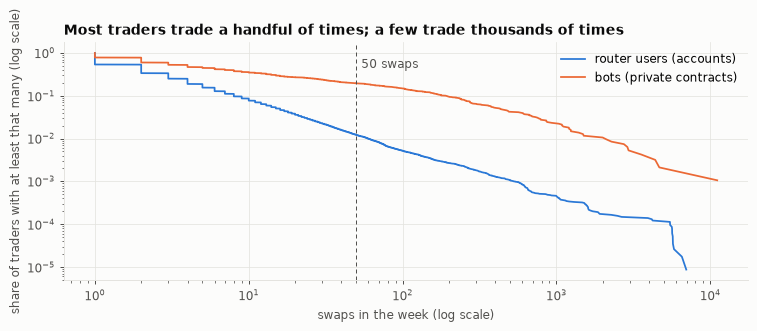

accounts that both operate a private contract and trade through public routers: 257


In [5]:
events = ta.add_symbols(ta.assign_traders(swaps, callers))
events["period"] = np.select([events["block"] < TRAIN_END, events["block"] < DEV_END], ["train", "dev"], "test")
kind = events.drop_duplicates("trader").set_index("trader")["trader_kind"]
per_trader = events.groupby("trader").size()

rows = {}
for name in ["bot", "router_user"]:
    counts = per_trader[kind[per_trader.index] == name]
    rows[name] = {"traders": len(counts), "swaps": counts.sum(), "median swaps per trader": counts.median(),
                  "largest": counts.max(), "traders with at least 20 swaps": (counts >= 20).sum(),
                  "at least 50": (counts >= 50).sum(), "at least 200": (counts >= 200).sum(), "at least 1,000": (counts >= 1000).sum(),
                  "share of swaps from traders with at least 50 %": 100 * counts[counts >= 50].sum() / counts.sum()}
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
for name in ["router_user", "bot"]:
    counts = np.sort(per_trader[kind[per_trader.index] == name].to_numpy())
    ax.plot(counts, 1 - np.arange(len(counts)) / len(counts), color=KIND_COLOR[name], label={"bot": "bots (private contracts)", "router_user": "router users (accounts)"}[name])
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("swaps in the week (log scale)"); ax.set_ylabel("share of traders with at least that many (log scale)")
ax.axvline(MIN_TRAIN, color=MUTED, linewidth=0.8, linestyle=(0, (4, 3))); ax.annotate("50 swaps", (MIN_TRAIN, 1), xytext=(4, -12), textcoords="offset points", color=MUTED)
ax.set_title("Most traders trade a handful of times; a few trade thousands of times"); ax.legend()
fig.tight_layout(); plt.show()
both_roles = set(events.loc[events["trader_kind"] == "bot", "tx_from"]) & set(events.loc[events["trader_kind"] == "router_user", "trader"])
print(f"accounts that both operate a private contract and trade through public routers: {len(both_roles)}")

**Units.**

- A **bot** is a private contract; its sequence is every swap that contract made.
- A **router user** is a signing account; its sequence is every swap in the transactions it sent through
  public routers.
- Swaps through **unclear** callers are left out. That is 36% of all swaps: contracts used by a fleet of
  signing accounts (the most active pool caller of the week has 23 signers and 85,000 swaps), or by too few
  accounts to be a router and too many to be one operator's. Many of them are probably professional systems too. Leaving them out keeps the two groups
  clean at the cost of coverage.

**Sizes.** The week contains 115,000 router users and 944 private contracts, but **activity is extremely
skewed.** The median router user swaps twice in the week, the median private contract four times. Only
traders with at least 50 swaps can be modelled individually: 184 bots, which make 95% of all bot swaps, and
1,426 router users, which make 46% of theirs. This confirms the main risk named in the idea ("most addresses
have too few events to learn an automaton from") and fixes the scale of the study: hundreds of traders, not
tens of thousands.

### 2.1 Feature set and labels

| | Choice | Why |
| --- | --- | --- |
| **Observation** | A trader's swaps in chain order (block, position in block, position in transaction) | The raw material for a sequence model. |
| **Features** | One symbol per swap, describing it **relative to the trader's previous swap**: how long ago (5 levels) and in which pool and direction (4 levels), 20 symbols in all. Optionally the swap's size relative to other swaps in the same pool (3 levels). | Behaviour, not identity: the symbols say *how* a trader trades and deliberately not *which* pool or token. |
| **Labels, task A (identification)** | The trader's own address | Exact and free. "Is this later sequence from the same trader?" is what fingerprinting means. |
| **Labels, task B (bot or not)** | Private contract against router user | A proxy that does not depend on the action sequence. It is noisy: router users include automated traders, and some bots use routers. |
| **Not available** | Bot types (arbitrage, sandwich, market making) | The public label sources were unreachable. Rule-based type labels would also be circular: the rules read the same patterns the model would. |

## 3. From swaps to symbols, and the split

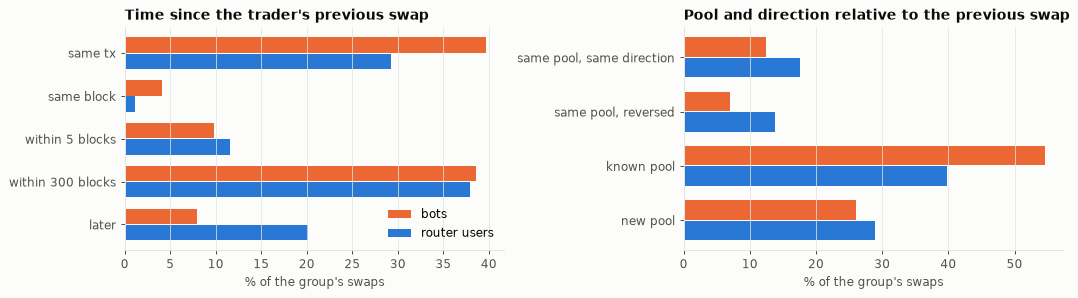

Symbols most over-represented among bots: [('same block / same pool, reversed', 62.5), ('same tx / same pool, same direction', 2.2), ('same tx / known pool', 1.6)]
Symbols most over-represented among router users: [('later / same pool, reversed', 4.5), ('within 5 blocks / same pool, reversed', 4.3), ('within 300 blocks / same pool, reversed', 3.2)]


In [6]:
symbols = events[events["symbol"] >= 0]
share = pd.crosstab(symbols["symbol"], symbols["trader_kind"], normalize="columns").reindex(range(N_SYMBOLS), fill_value=0)
gap_share = pd.crosstab(symbols["gap"], symbols["trader_kind"], normalize="columns")
relation_share = pd.crosstab(symbols["relation"], symbols["trader_kind"], normalize="columns")
gap_share.index, relation_share.index = ta.GAP_NAMES, ta.RELATION_NAMES

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, table, title in [(axes[0], gap_share, "Time since the trader's previous swap"), (axes[1], relation_share, "Pool and direction relative to the previous swap")]:
    y = np.arange(len(table))
    ax.barh(y - 0.19, 100 * table["bot"], height=0.36, color=ORANGE, label="bots")
    ax.barh(y + 0.19, 100 * table["router_user"], height=0.36, color=BLUE, label="router users")
    ax.set_yticks(y); ax.set_yticklabels(table.index); ax.invert_yaxis(); ax.set_xlabel("% of the group's swaps"); ax.set_title(title); ax.grid(axis="y", visible=False)
axes[0].legend(loc="lower right")
fig.tight_layout(); plt.show()

largest = (share["bot"] / share["router_user"]).replace([np.inf, 0], np.nan).dropna().sort_values()
print("Symbols most over-represented among bots:", [(ta.symbol_name(i), round(r, 1)) for i, r in largest.tail(3)[::-1].items()])
print("Symbols most over-represented among router users:", [(ta.symbol_name(i), round(1 / r, 1)) for i, r in largest.head(3).items()])

### 3.1 What the exploratory analysis shows

- **The two groups use the same symbols in broadly similar proportions.** There is no single give-away.
  Both make many multi-swap transactions ("same tx"): a routed trade through several pools looks, at this
  level, like an arbitrage through several pools.
- **A few symbols are strongly characteristic.** The clearest is "same block, same pool, reversed": buying
  and selling the same pool in two transactions of one block, which is the footprint of a sandwich. It is
  rare overall and about 60 times more frequent among private contracts. Router users, in turn, more often
  return to the same pool in the opposite direction after minutes or hours: buying a token and selling it
  later.
- **Timing differs less than expected** from the literature on bots. Part of the reason is the composition
  of the "router user" group, which includes heavy automated users.

### 3.2 Preprocessing decisions

| Issue found in the data | Decision |
| --- | --- |
| Pool callers that are neither clearly public nor clearly private | Their swaps are dropped. Documented as a coverage limit. |
| Accounts with thousands of swaps through public routers | Kept as router users. They are almost certainly automated, which makes the bot label noisy. Results are also reported per group. |
| Accounts that sign for a private contract and also use routers | For the split by trader, a bot and its operator's account always fall in the same part. |
| Extremely skewed activity | Models are fitted per trader only for traders with at least 50 symbols in train. Queries are truncated to their first 100 symbols, so that long sequences do not win by length. |
| Pool and token identity would identify a trader trivially | Excluded from the symbols. Used only in a separate reference model. |
| No prices or token decimals | Size is the swap's rank among the swaps of the same pool, not a dollar amount. |
| A trader's first swap has no predecessor | It gets no symbol. |
| Swaps inside one transaction | Ordered by their position in the transaction. |

In [7]:
def period_sequences(period, alphabet="gap_relation"):
    return ta.sequences_by_trader(events[events["period"] == period], alphabet)

def identification_setup(query_period, alphabet="gap_relation"):
    # Traders with enough symbols in train and in the query period; queries truncated.
    train_seq, query_seq = period_sequences("train", alphabet), period_sequences(query_period, alphabet)
    traders = [t for t, seq in train_seq.items() if len(seq) >= MIN_TRAIN and len(query_seq.get(t, ())) >= MIN_QUERY]
    return {t: train_seq[t] for t in traders}, {t: query_seq[t][:QUERY_LENGTH] for t in traders}

# Trader groups for task B: a bot and its operator's account share a group.
operator = events.groupby("trader")["tx_from"].agg(lambda accounts: accounts.mode().iloc[0])
trader_group = operator.map(ta.assign_groups(operator.unique()))

split_rows = {}
for period, first, last in [("train", START_BLOCK, TRAIN_END - 1), ("dev", TRAIN_END, DEV_END - 1), ("test", DEV_END, START_BLOCK + N_BLOCKS - 1)]:
    part = events[events["period"] == period]
    row = {"first block": first, "last block": last, "from": part["timestamp"].min().strftime("%m-%d %H:%M"), "to": part["timestamp"].max().strftime("%m-%d %H:%M"),
           "swaps": len(part), "bots active": part.loc[part["trader_kind"] == "bot", "trader"].nunique(),
           "router users active": part.loc[part["trader_kind"] == "router_user", "trader"].nunique()}
    if period != "train":
        enrolled, _ = identification_setup(period)
        row["task A: traders enrolled and queried"] = len(enrolled)
        row["of which bots"] = int((kind[list(enrolled)] == "bot").sum())
    split_rows[period] = row
split_table = pd.DataFrame(split_rows).T

# Save the symbolized events with their period and trader group (data/ is ignored by git).
out = events[["block", "tx_index", "log_index", "tx_hash", "trader", "trader_kind", "pool", "gap", "relation", "size", "symbol", "period"]].copy()
out["trader_group"] = out["trader"].map(trader_group)
out.to_parquet(ds.DATA_DIR / "events_with_symbols.parquet")
display(split_table)
print("Task B, traders per group and kind (all activity levels):")
pd.crosstab(trader_group.rename("group"), kind.rename("kind")).loc[["train", "dev", "test"]]

,first block,last block,from,to,swaps,bots active,router users active,task A: traders enrolled and queried,of which bots
train,26100000,26128799,10-01 20:56,10-05 21:16,466594,715,71655,NaN,NaN
dev,26128800,26135999,10-05 21:16,10-06 21:22,115313,333,24684,306,63
test,26136000,26150399,10-06 21:23,10-08 21:34,249614,563,44736,494,107


Task B, traders per group and kind (all activity levels):


kind,bot,router_user
group,,
train,575,68901
dev,175,23169
test,194,23012


### 3.3 The split

**By time, for both tasks:** train is the first four days, dev the fifth, test the last two. A model of a
trader is always fitted on that trader's earlier swaps and applied to later ones.

**Task A (identification)** needs nothing more: each eligible trader is enrolled with its train sequence and
queried with its dev or test sequence. The same traders appear on both sides by design, since recognizing
them again is the task.

**Task B (bot or not) is also split by trader.** Traders are assigned to train, dev and test groups by a
hash of their operator's address, 60 / 20 / 20. Class models are fitted on train-group traders in the train
period and evaluated on dev-group traders in the dev period (and test-group traders in the test period), so
no trader and no operator is on both sides.

### 3.4 Leakage checklist

| Risk | How it is handled |
| --- | --- |
| A symbol uses the trader's future | Every symbol looks only at the trader's previous swap and at which pools it used before (`ta.add_symbols`, tested by appending later events). |
| Identity leaks through the symbols | Symbols contain no address, pool or token. The reference model that does use pools is reported separately and labeled as such. |
| Task A: train and query overlap in time | They are disjoint periods. |
| Task B: the same trader, or the same operator's second contract, on both sides | Traders are grouped by operator before splitting. Operators using several signing accounts would still escape this. |
| Task B: the label is a function of the features | The label comes from who calls the pool, not from the sequence of swaps. But the two are not independent: how a trader reaches the pool shapes, for example, how many swaps share a transaction. |
| The bot / router definition uses the whole week | Who is a public router is decided from all seven days, test period included. This fixes the units, not the models, but it is information from the future. |
| Sequence length gives the class away | Queries are truncated to 100 symbols and scored per symbol. |
| Heavy traders dominate pooled class models | Each trader contributes at most 200 symbols to a class model. |
| Tuning on test | Candidate models are scored on dev only. Test is used for the fixed baselines. |

## 4. Baseline

### 4.1 Tasks, metrics and protocol

**Task A, identification (primary).** Given a later sequence of 100 symbols, say which of the enrolled
traders produced it.

**Task B, bot or not (secondary).** Given a sequence of 100 symbols from a trader never seen before, say
whether it is a private contract or a router user.

**Metrics.**

| Metric | Task | Why |
| --- | --- | --- |
| **Top-1 accuracy** (main), top-5, mean reciprocal rank | A | Identification is a ranking problem: every enrolled trader is a candidate. Top-1 is the share recognized outright, the others show how close the misses are. Chance is one over the number of candidates. |
| **ROC AUC** and average precision for the bot class | B | Threshold-free, and average precision respects the imbalance (bots are the minority). |
| Bootstrap intervals over query traders | both | The samples are small; differences between models must be judged against this noise. |
| Number of states | automata | Compactness and readability are the reason to use automata, so size is reported next to accuracy. |

**Protocol.** Fit each trader's model on its train-period symbols; score dev queries, then test queries.
No refitting. For task B, pooled class models as described in section 3.3.

**Baselines.**

| Model | What it uses |
| --- | --- |
| Chance | Nothing. |
| **Symbol frequencies (the fixed baseline)** | How often each of the 20 symbols occurs, ignoring their order. For task A a per-trader unigram model; for task B a logistic regression on the 20 frequencies. |
| Pool profile (reference, task A) | Which pools the trader uses. Not a behavioural model: it shows what identity information lies in *where* someone trades. |

The baseline that matters is the symbol-frequency one. **A sequence model, automaton or not, is only
justified if it beats a model that ignores order.**

In [8]:
def pool_sequences(period):
    part = events[(events["period"] == period) & (events["symbol"] >= 0)]
    return {t: pools.to_numpy() for t, pools in part.groupby("trader", sort=False)["pool"]}

def bootstrap_top1(ranks, n_boot=2000, seed=0):
    hits = (np.asarray(ranks) == 1).astype(float)
    rng = np.random.default_rng(seed)
    means = hits[rng.integers(0, len(hits), (n_boot, len(hits)))].mean(axis=1)
    return np.quantile(means, [0.025, 0.975])

unigram = lambda: ta.NGramModel(order=0)
baseline_rows, baseline_ranks = {}, {}
for period in ["dev", "test"]:
    enrolled, queries = identification_setup(period)
    traders = list(enrolled)
    train_pools, query_pools = pool_sequences("train"), pool_sequences(period)
    runs = {
        "Symbol frequencies (fixed baseline)": ta.identification_scores(enrolled, queries, unigram),
        "Pool profile (reference)": ta.identification_scores({t: train_pools[t] for t in traders}, {t: query_pools[t][:QUERY_LENGTH] for t in traders}, ta.PoolProfile),
    }
    baseline_rows[(period, "Chance")] = {"traders": len(traders), "top-1": 1 / len(traders), "top-5": 5 / len(traders)}
    for name, scores in runs.items():
        metrics, ranks = ta.identification_metrics(scores), ta.identification_ranks(scores)
        low, high = bootstrap_top1(ranks)
        baseline_ranks[(period, name)] = ranks
        baseline_rows[(period, name)] = {"traders": len(traders), "top-1": metrics["top1"], "top-1 95% interval": f"{low:.2f} to {high:.2f}",
                                         "top-5": metrics["top5"], "mean reciprocal rank": metrics["mrr"]}
baseline_table = pd.DataFrame(baseline_rows).T
print("Task A: identify a trader from 100 later symbols")
baseline_table

Task A: identify a trader from 100 later symbols


traders top-1 top-5 top-1 95% interval mean reciprocal rank
dev  Chance                              306.000 0.003 0.016                NaN                  NaN
     Symbol frequencies (fixed baseline)     306 0.307 0.578       0.26 to 0.36                0.441
     Pool profile (reference)                306 0.353 0.611       0.30 to 0.41                0.471
test Chance                              494.000 0.002 0.010                NaN                  NaN
     Symbol frequencies (fixed baseline)     494 0.231 0.494       0.19 to 0.27                0.358
     Pool profile (reference)                494 0.312 0.532       0.27 to 0.35                0.421

### 4.2 How the baseline performs (task A)

- **Behaviour identifies traders far better than chance, without using a single address or pool.** From 100
  symbols, the frequency baseline puts the right trader first for 31% of the 306 dev traders and 23% of the
  494 test traders, where random guessing would be right 0.3% and 0.2% of the time. The right trader is
  among the top five in 58% and 49% of cases.
- **Where a trader trades identifies it somewhat better than how:** the pool profile reaches 35% on dev and
  31% on test. A practical fingerprint would combine both. The behavioural models are the object of this
  study because they are what transfers when a trader moves to new pools or a new address.
- **Accuracy is lower on test than on dev.** Test has more candidates to confuse (494 against 306) and lies
  further from the training period, so the two effects cannot be separated here.

## 5. Method fit: do automata add anything?

### 5.1 Order of symbols, and automata, on task A

Three candidates, all scored on dev: a bigram model (each symbol given the previous one), a trigram model
(given the previous two), and a probabilistic automaton learned per trader with ALERGIA.

In [9]:
enrolled, queries = identification_setup("dev")
start = time.time()
candidate_scores = {
    "Symbol frequencies (fixed baseline)": ta.identification_scores(enrolled, queries, unigram),
    "Bigram": ta.identification_scores(enrolled, queries, lambda: ta.NGramModel(order=1)),
    "Trigram": ta.identification_scores(enrolled, queries, lambda: ta.NGramModel(order=2)),
    "Automaton (ALERGIA, window 4)": ta.identification_scores(enrolled, queries, lambda: ta.PdfaModel(window=4)),
    "Automaton (ALERGIA, window 6)": ta.identification_scores(enrolled, queries, lambda: ta.PdfaModel(window=6)),
}
print(f"{len(enrolled)} traders, {time.time() - start:.0f}s")

automata = {t: ta.PdfaModel(window=4).fit(seq) for t, seq in enrolled.items()}
parameters = {
    "Symbol frequencies (fixed baseline)": N_SYMBOLS - 1, "Bigram": (N_SYMBOLS + 1) * (N_SYMBOLS - 1), "Trigram": (N_SYMBOLS + 1) ** 2 * (N_SYMBOLS - 1),
    "Automaton (ALERGIA, window 4)": f"{np.median([sum(len(m) for m in a.transitions) for a in automata.values()]):.0f} (median)",
    "Automaton (ALERGIA, window 6)": "",
}
base_hits = (ta.identification_ranks(candidate_scores["Symbol frequencies (fixed baseline)"]) == 1).to_numpy().astype(float)
rng = np.random.default_rng(0)
resample = rng.integers(0, len(base_hits), (2000, len(base_hits)))
rows = {}
for name, scores in candidate_scores.items():
    metrics, ranks = ta.identification_metrics(scores), ta.identification_ranks(scores)
    hits = (ranks == 1).to_numpy().astype(float)
    low, high = bootstrap_top1(ranks)
    diff = (hits - base_hits)[resample].mean(axis=1)
    rows[name] = {"top-1": metrics["top1"], "95% interval": f"{low:.2f} to {high:.2f}", "top-5": metrics["top5"], "mean reciprocal rank": metrics["mrr"],
                  "top-1 minus baseline": hits.mean() - base_hits.mean(),
                  "interval of the difference": "" if name.startswith("Symbol") else f"{np.quantile(diff, 0.025):+.2f} to {np.quantile(diff, 0.975):+.2f}",
                  "free parameters or transitions": parameters[name]}
candidates = pd.DataFrame(rows).T
print(f"Task A on dev; median automaton size: {np.median([a.n_states for a in automata.values()]):.0f} states")
candidates

306 traders, 11s


Task A on dev; median automaton size: 13 states


,top-1,95% interval,top-5,mean reciprocal rank,top-1 minus baseline,interval of the difference,free parameters or transitions
Symbol frequencies (fixed baseline),0.307,0.26 to 0.36,0.578,0.441,0.000,,19
Bigram,0.324,0.27 to 0.37,0.542,0.433,0.016,-0.03 to +0.06,399
Trigram,0.271,0.22 to 0.32,0.451,0.369,-0.036,-0.09 to +0.02,8379
"Automaton (ALERGIA, window 4)",0.317,0.26 to 0.37,0.520,0.418,0.010,-0.04 to +0.06,63 (median)
"Automaton (ALERGIA, window 6)",0.314,0.26 to 0.36,0.523,0.417,0.007,-0.04 to +0.06,


In [10]:
# What drives the result: alphabet, query length, and kind of trader.
alphabet_rows = {}
for alphabet, size in ta.ALPHABETS.items():
    enrolled_a, queries_a = identification_setup("dev", alphabet)
    alphabet_rows[alphabet] = {
        "symbols": size,
        "frequencies: top-1": ta.identification_metrics(ta.identification_scores(enrolled_a, queries_a, lambda: ta.NGramModel(0, n_symbols=size)))["top1"],
        "bigram: top-1": ta.identification_metrics(ta.identification_scores(enrolled_a, queries_a, lambda: ta.NGramModel(1, n_symbols=size)))["top1"],
    }
print("Alphabet (dev):")
display(pd.DataFrame(alphabet_rows).T)

length_rows = {}
for length in [10, 20, 50, 100]:
    short = {t: q[:length] for t, q in queries.items()}
    length_rows[length] = {"frequencies: top-1": ta.identification_metrics(ta.identification_scores(enrolled, short, unigram))["top1"],
                           "bigram: top-1": ta.identification_metrics(ta.identification_scores(enrolled, short, lambda: ta.NGramModel(1)))["top1"]}
print("Query length in symbols (dev):")
display(pd.DataFrame(length_rows).T.rename_axis("query length"))

by_kind = pd.DataFrame({name: (ta.identification_ranks(scores) == 1).groupby(kind[scores.index]).mean() for name, scores in candidate_scores.items()}).T
by_kind["traders: bot / router user"] = f"{int((kind[list(enrolled)] == 'bot').sum())} / {int((kind[list(enrolled)] == 'router_user').sum())}"
print("Top-1 by kind of trader (dev):")
by_kind

Alphabet (dev):


,symbols,frequencies: top-1,bigram: top-1
gap,5.000,0.141,0.186
relation,4.000,0.088,0.114
gap_relation,20.000,0.307,0.324
gap_relation_size,60.000,0.376,0.261


Query length in symbols (dev):


,frequencies: top-1,bigram: top-1
query length,,
10,0.157,0.173
20,0.216,0.271
50,0.265,0.297
100,0.307,0.324


Top-1 by kind of trader (dev):


trader_kind,bot,router_user,traders: bot / router user
Symbol frequencies (fixed baseline),0.429,0.276,63 / 243
Bigram,0.524,0.272,63 / 243
Trigram,0.476,0.218,63 / 243
"Automaton (ALERGIA, window 4)",0.492,0.272,63 / 243
"Automaton (ALERGIA, window 6)",0.476,0.272,63 / 243


In [11]:
# Do the automata remember more than the previous swap? Compare states with symbols used.
structure = pd.DataFrame({
    "train symbols": {t: len(seq) for t, seq in enrolled.items()},
    "distinct symbols used": {t: len(set(seq.tolist())) for t, seq in enrolled.items()},
    "states": {t: a.n_states for t, a in automata.items()},
})
structure["states beyond one per symbol"] = structure["states"] - structure["distinct symbols used"] - 1   # minus the start state
print(f"automata with exactly one state per symbol used (plus the start state): {100 * (structure['states beyond one per symbol'] == 0).mean():.0f}% of {len(structure)}")
print(f"mean number of extra states: {structure['states beyond one per symbol'].mean():.2f}; among the {int((structure['train symbols'] >= 2000).sum())} traders with at least 2,000 train symbols: {structure.loc[structure['train symbols'] >= 2000, 'states beyond one per symbol'].mean():.2f}")
display(structure.describe().loc[["min", "50%", "max"]])

# How readable is a learned automaton? The most active bot, as an example.
example = max((t for t in enrolled if kind[t] == "bot"), key=lambda t: len(enrolled[t]))
automaton = automata[example]
table = automaton.describe(top=3)
name = lambda s: "(start)" if s == ta.PdfaModel.START else ta.symbol_name(s)
table["entered by"] = table["entered_by"].map(name)
table["most likely next swaps"] = table["next"].map(lambda moves: "; ".join(f"{name(s)} {100 * p:.0f}% -> state {target}" for s, p, target in moves))
print(f"Bot {example}: {len(enrolled[example]):,} train symbols, automaton with {automaton.n_states} states and {sum(len(m) for m in automaton.transitions)} transitions")
print(f"Sizes over all {len(automata)} enrolled traders: median {np.median([a.n_states for a in automata.values()]):.0f} states, largest {max(a.n_states for a in automata.values())}")
table[["state", "entered by", "n_next", "most likely next swaps"]].head(12)

automata with exactly one state per symbol used (plus the start state): 88% of 306
mean number of extra states: 0.16; among the 20 traders with at least 2,000 train symbols: 0.80


,train symbols,distinct symbols used,states,states beyond one per symbol
min,51.000,1.000,2.000,0.000
50%,257.500,12.000,13.000,0.000
max,"7,236.000",19.000,20.000,2.000


Bot 0x1f2f10d1c40777ae1da742455c65828ff36df387: 7,236 train symbols, automaton with 19 states and 186 transitions
Sizes over all 306 enrolled traders: median 13 states, largest 20


,state,entered by,n_next,most likely next swaps
0,0,(start),16,same tx / known pool 40% -> state 3; within 300 blocks / known pool 16% -> state 15; within 5 blocks / known pool 12...
1,1,"same tx / same pool, same direction",10,same tx / known pool 40% -> state 3; within 300 blocks / known pool 19% -> state 15; within 5 blocks / known pool 13...
2,2,"same tx / same pool, reversed",5,"same tx / known pool 67% -> state 3; within 5 blocks / known pool 13% -> state 11; same tx / same pool, reversed 7% ..."
3,3,same tx / known pool,15,same tx / known pool 44% -> state 3; within 300 blocks / known pool 18% -> state 15; within 5 blocks / known pool 14...
4,4,same tx / new pool,12,same tx / known pool 36% -> state 18; same tx / new pool 29% -> state 4; within 300 blocks / known pool 10% -> state 15
5,5,"same block / same pool, same direction",6,"same block / same pool, reversed 50% -> state 6; within 5 blocks / known pool 17% -> state 11; within 300 blocks / k..."
6,6,"same block / same pool, reversed",12,within 300 blocks / known pool 38% -> state 15; within 5 blocks / known pool 21% -> state 11; same tx / known pool 1...
7,7,same block / known pool,13,same tx / known pool 42% -> state 3; within 300 blocks / known pool 22% -> state 15; within 5 blocks / known pool 14...
8,8,same block / new pool,3,same tx / new pool 71% -> state 4; within 5 blocks / known pool 14% -> state 11; within 300 blocks / known pool 14% ...
9,9,"within 5 blocks / same pool, same direction",11,"within 5 blocks / same pool, same direction 26% -> state 9; same tx / known pool 20% -> state 3; within 300 blocks /..."


**Reading the results of task A.**

- **Order adds little, and automata add nothing beyond that.** Top-1 accuracy is 31% for the frequency
  baseline, 32% for the bigram model and for the automata, 27% for the trigram model. Every difference from
  the baseline has an interval that includes zero (for the bigram model -0.03 to +0.06). With 306 traders,
  no sequence model is distinguishable from the model that ignores order.
- **The learned automata are first-order Markov chains.** For 88% of the traders the automaton has exactly
  one state per symbol the trader uses: ALERGIA merged every deeper distinction as statistically
  unsupported. Even for the 20 traders with more than 2,000 train symbols it adds less than one extra state
  on average. So the automaton is a bigram model with the unused transitions left out, which explains why
  the two score the same. Loosening the merge test produces more states, but, in a check on part of the
  data during exploration, no gain in accuracy.
- **They are compact:** a median of 13 states and 63 transitions, against 399 free parameters of the bigram
  model, at the same accuracy. That is the one advantage found.
- **They are readable only in the trivial sense.** In the example above each state is "the last swap was of
  kind X", and its row says what tends to follow. That is a readable table of habits (after a swap in the
  same transaction, 44% another one; after a same-block reversal, a pause), but not the hidden strategy
  states the idea hoped to read off.
- **The alphabet matters more than the model.** Time gaps alone give 14%, pool relations alone 9%, their
  combination 31%. Adding swap size raises the frequency model to 38% and lowers the bigram model to 26%,
  which then has too many parameters for the data. Better symbols gain more than better sequence models.
- **Accuracy grows with the length of the query** and has not levelled off: 16% from 10 symbols, 27% from
  50, 31% from 100.
- **Bots are easier to recognize than router users** (43% against 28% for the baseline). For the 63 bots
  the bigram model reaches 52%, the only hint that order matters for some traders, on a sample too small
  to confirm it.

### 5.2 Task B: bot or not

In [12]:
CAP = 200   # symbols per trader that go into a class model

def group_sequences(period, group):
    return {t: seq for t, seq in period_sequences(period).items() if trader_group[t] == group and len(seq) >= MIN_QUERY}

fit_set = group_sequences("train", "train")
is_bot = lambda traders: np.array([kind[t] == "bot" for t in traders])
frequencies = lambda seq: np.bincount(seq[:QUERY_LENGTH], minlength=N_SYMBOLS) / len(seq[:QUERY_LENGTH])

def class_models(make):
    bots = make().fit_many([seq[:CAP] for t, seq in fit_set.items() if kind[t] == "bot"])
    users = make().fit_many([seq[:CAP] for t, seq in fit_set.items() if kind[t] == "router_user"])
    return bots, users

def likelihood_ratio(models, eval_set):
    bots, users = models
    return np.array([bots.mean_log_likelihood(seq[:QUERY_LENGTH]) - users.mean_log_likelihood(seq[:QUERY_LENGTH]) for seq in eval_set.values()])

def auc_interval(y, scores, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    values = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if 0 < y[idx].sum() < len(idx):
            values.append(roc_auc_score(y[idx], scores[idx]))
    return np.quantile(values, [0.025, 0.975])

logistic = LogisticRegression(max_iter=2000, class_weight="balanced", C=10).fit(np.array([frequencies(s) for s in fit_set.values()]), is_bot(fit_set))
frequency_models = class_models(unigram)
candidates_b = {"Bigram likelihood ratio": lambda: ta.NGramModel(1), "Trigram likelihood ratio": lambda: ta.NGramModel(2),
                "Automaton likelihood ratio (ALERGIA, window 4)": lambda: ta.PdfaModel(window=4)}

rows = {}
for period in ["dev", "test"]:
    eval_set = group_sequences(period, period)
    y = is_bot(eval_set)
    runs = {"Symbol frequencies, logistic regression (fixed baseline)": logistic.predict_proba(np.array([frequencies(s) for s in eval_set.values()]))[:, 1],
            "Symbol frequencies, likelihood ratio": likelihood_ratio(frequency_models, eval_set)}
    if period == "dev":   # candidates are scored on dev only
        for name, make in candidates_b.items():
            models = class_models(make)
            runs[name] = likelihood_ratio(models, eval_set)
            if hasattr(models[0], "n_states"):
                print(f"class automata: {models[0].n_states} states for bots, {models[1].n_states} for router users")
    for name, scores in runs.items():
        low, high = auc_interval(y, scores)
        rows[(period, name)] = {"traders": len(y), "bots": int(y.sum()), "ROC AUC": roc_auc_score(y, scores), "AUC 95% interval": f"{low:.2f} to {high:.2f}",
                                "average precision": average_precision_score(y, scores), "bot share (chance level of AP)": y.mean()}
print(f"class models fitted on {len(fit_set)} train-group traders ({int(is_bot(fit_set).sum())} bots)")
pd.DataFrame(rows).T

class automata: 57 states for bots, 124 for router users


class models fitted on 987 train-group traders (104 bots)


traders bots ROC AUC AUC 95% interval average precision bot share (chance level of AP)
dev  Symbol frequencies, logistic regression (fixed baseline)      64   17   0.745     0.61 to 0.86             0.478                          0.266
     Symbol frequencies, likelihood ratio                          64   17   0.824     0.69 to 0.92             0.712                          0.266
     Bigram likelihood ratio                                       64   17   0.900     0.80 to 0.97             0.758                          0.266
     Trigram likelihood ratio                                      64   17   0.839     0.71 to 0.94             0.700                          0.266
     Automaton likelihood ratio (ALERGIA, window 4)                64   17   0.847     0.72 to 0.95             0.735                          0.266
test Symbol frequencies, logistic regression (fixed baseline)     171   23   0.781     0.71 to 0.85             0.303                          0.135
     Symbol frequencies, likelihood ratio                         171   23   0.640     0.51 to 0.76             0.309                          0.135

**Reading the results of task B.**

- **Private contracts can be told from router users above chance** from 100 symbols of behaviour: the
  logistic regression on symbol frequencies has an AUC of 0.75 on dev and 0.78 on test.
- **The evaluation set is too small to rank the models, and too small to be stable.** After requiring unseen
  traders with enough activity, 17 bots remain in dev and 23 in test. The intervals of the AUC are wide and
  overlap for all models: the bigram likelihood ratio leads on dev (0.90, interval 0.80 to 0.97), but the
  frequency likelihood ratio that scores 0.82 on dev scores 0.64 on test. Nothing can be said about whether
  order or automata help here.
- **The label is a proxy.** A high score shows that traders with their own contract behave differently from
  traders using routers, not that the model has found "bots" in a wider sense.

## 6. Summary

| Question | Answer |
| --- | --- |
| Is the data usable? | Yes. One week of swap events from public endpoints: complete, consistent, no key needed. Not covered: other exchange designs, prices, and any bot labels. |
| Is there enough? | Events, yes: 1.29 million swaps. Traders with enough events to model, few: 306 on dev and 494 on test for identification. Bots unseen in training for the bot task: 17 and 23. |
| Features and labels? | 20 symbols describing each swap relative to the trader's previous one. Labels: the trader's identity (exact), and private contract against router user (a proxy). |
| Preprocessing? | Traders defined by who calls the pool; unclear callers dropped; identity kept out of the symbols; queries truncated to 100 symbols. |
| Split? | By time (four days, one day, two days), and for the bot task also by trader, grouped by operator. |
| Baseline? | Symbol frequencies, ignoring order. It identifies the right trader among 306 in 31% of cases on dev and among 494 in 23% on test (chance: 0.3% and 0.2%). |
| Do automata fit? | They can be learned and they are small (median 13 states). But they collapse to first-order Markov chains, and they do not beat the frequency baseline or a bigram model on either task at this data size. |

The full discussion is in [`research/bot_fingerprinting_writeup.md`](../../research/bot_fingerprinting_writeup.md).